Using model: openai/gpt-oss-120b
Key OK.
=== 1) Normal run ===
Report v1:
 **Report – How Companies Are Using AI Agents in Customer Support**  
*Prepared Oct 15 2026*  

---

## 1. Types of AI Agents Deployed

| Agent Type | Typical Form‑factor | Core Capabilities | Representative Platforms |
|------------|--------------------|-------------------|--------------------------|
| **Text‑based chatbots** | Web‑widget, mobile app, messaging apps (WhatsApp, FB Messenger, Slack) ...

=== 2) INSPECT: checkpoints of this thread ===

 #  checkpoint     parent         next node(s)                 state
 0  1f1c87b7-e7ad  -              __start__                    tasks=0 results=0 merged=no report=no
 1  1f1c87b7-e7af  1f1c87b7-e7ad  planner                      tasks=0 results=0 merged=no report=no
 2  1f1c87b7-f2c6  1f1c87b7-e7af  validate                     tasks=3 results=0 merged=no report=no
 3  1f1c87b7-f2cb  1f1c87b7-f2c6  worker_1, worker_2, worker_3 tasks=3 results=0 merged=no report=n

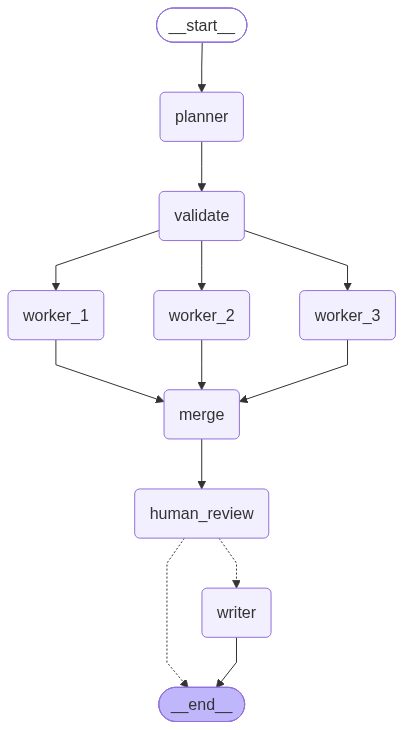

In [13]:
"""
ALL-IN-ONE: Parallel research agent + checkpoint Time Travel demo (LangGraph).
One file / one notebook cell. No imports between files needed.

pip install langgraph langchain-groq
Run it: the key is asked at runtime (getpass), then the demo runs:
  1) normal run  2) inspect checkpoints  3) replay  4) fork  5) print graph
"""
import json
import re
import time
from getpass import getpass
from typing import Annotated, Literal, TypedDict

from langchain_groq import ChatGroq
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command, interrupt

MODEL = None  # set a model id here to force it, e.g. "openai/gpt-oss-120b"
PREFERRED_MODELS = [  # first one available on your account is used
    "llama-3.3-70b-versatile",
    "openai/gpt-oss-120b",
    "openai/gpt-oss-20b",
    "qwen/qwen3-32b",
    "llama-3.1-8b-instant",
]
NUM_WORKERS = 3          # number of parallel worker nodes (= max tasks)
MAX_RETRIES = 3
MAX_PARALLEL_WORKERS = 2  # concurrency limit (applied at invoke time)

llm = None  # created in init_llm()


def pick_model(key: str) -> str:
    """Ask Groq which models this key can use, and choose one."""
    import httpx

    r = httpx.get("https://api.groq.com/openai/v1/models",
                  headers={"Authorization": f"Bearer {key}"}, timeout=20)
    r.raise_for_status()
    available = [m["id"] for m in r.json()["data"]]
    for m in PREFERRED_MODELS:
        if m in available:
            return m
    print("Available models on your account:")
    for m in sorted(available):
        print("  ", m)
    raise SystemExit("None of PREFERRED_MODELS available. Set MODEL to one of the chat models above.")


def init_llm() -> None:
    """Ask for the key, build the LLM, and fail fast with a clear message."""
    global llm
    key = getpass("Groq API key (gsk_...): ").strip()
    if not key.startswith("gsk_"):
        raise SystemExit("That is not a Groq key (Groq keys start with 'gsk_').")
    model = MODEL or pick_model(key)
    print("Using model:", model)
    llm = ChatGroq(model=model, temperature=0, api_key=key, max_retries=3, timeout=30)
    try:
        llm.invoke("Reply with: ok")  # preflight check
    except Exception as e:
        raise SystemExit(f"Groq rejected the key or is unreachable: {e}")
    print("Key OK.")


# ---------- LLM helpers (swap in Tavily search etc. inside answer_task) ----------
def parse_tasks(text: str) -> list[str]:
    """Pull a task list out of model text: JSON array first, else numbered/bulleted lines."""
    m = re.search(r"\[.*\]", text, re.S)
    if m:
        try:
            items = json.loads(m.group(0))
            if isinstance(items, list) and all(isinstance(i, str) for i in items):
                return [i.strip() for i in items if i.strip()]
        except json.JSONDecodeError:
            pass
    lines = [l.replace("**", "").strip() for l in text.splitlines()]
    item = re.compile(r"^(?:\d+[.)]|[-*•])\s+")
    items = [item.sub("", l).strip() for l in lines if item.match(l)]
    if not items:
        items = [l for l in lines if len(l) > 10 and not l.endswith(":")]
    return [i for i in items if len(i) > 10]


def plan_tasks(question: str) -> list[str]:
    text = llm.invoke(
        f"Break this research question into exactly {NUM_WORKERS} independent "
        f"sub-questions.\nReturn ONLY a JSON array of strings, nothing else.\n\n"
        f"Question: {question}"
    ).content
    tasks = parse_tasks(text)
    if not tasks:
        raise ValueError(f"Planner returned no usable tasks. Model said:\n{text[:300]}")
    return tasks


def answer_task(task: str) -> str:
    return llm.invoke(f"Research this briefly and factually:\n{task}").content


def write_report(question: str, merged: str) -> str:
    return llm.invoke(
        f"Write a short report answering: {question}\n\nFindings:\n{merged}"
    ).content


# ---------- Reducer: merges concurrent worker writes instead of overwriting ----------
def merge_results(left: list[dict], right: list[dict]) -> list[dict]:
    """Append new results, deduplicate by task (first result wins)."""
    seen = {r["task"] for r in left}
    return left + [r for r in right if r["task"] not in seen]


# ---------- State ----------
class State(TypedDict):
    question: str
    tasks: list[str]
    results: Annotated[list[dict], merge_results]  # <- reducer lives here
    merged: str
    report: str


# ---------- Nodes ----------
def planner(state: State):
    return {"tasks": plan_tasks(state["question"])}


def validate(state: State):
    """Plain business logic, no LLM: drop empty/duplicate tasks, cap the count."""
    seen, clean = set(), []
    for t in state["tasks"]:
        key = t.strip().lower()
        if key and key not in seen:
            seen.add(key)
            clean.append(t.strip())
    return {"tasks": clean[:NUM_WORKERS]}


def make_worker(i: int):
    """Worker i handles tasks[i]. All workers start at the same time."""
    def worker(state: State):
        if i >= len(state["tasks"]):
            return {"results": []}  # nothing for this worker
        task = state["tasks"][i]
        for attempt in range(1, MAX_RETRIES + 1):
            try:
                answer = answer_task(task)
                return {"results": [{"task": task, "status": "ok", "answer": answer}]}
            except Exception as e:
                if attempt == MAX_RETRIES:
                    # failure route: record it, don't kill the whole run
                    return {"results": [{"task": task, "status": "failed", "answer": str(e)}]}
                time.sleep(2 ** attempt)
    return worker


def merge(state: State):
    ok = [r for r in state["results"] if r["status"] == "ok"]
    failed = [r["task"] for r in state["results"] if r["status"] == "failed"]
    merged = "\n\n".join(f"## {r['task']}\n{r['answer']}" for r in ok)
    if failed:
        merged += "\n\n[Failed tasks: " + "; ".join(failed) + "]"
    return {"merged": merged}


def human_review(state: State) -> Command[Literal["writer", "__end__"]]:
    decision = interrupt(
        {"message": "Approve findings before writing the report?", "merged": state["merged"]}
    )
    return Command(goto="writer" if decision else END)


def writer(state: State):
    return {"report": write_report(state["question"], state["merged"])}


# ---------- Graph ----------
def build_graph():
    g = StateGraph(State)
    g.add_node("planner", planner)
    g.add_node("validate", validate)
    worker_names = [f"worker_{i + 1}" for i in range(NUM_WORKERS)]
    for i, name in enumerate(worker_names):
        g.add_node(name, make_worker(i))
    g.add_node("merge", merge)
    g.add_node("human_review", human_review)
    g.add_node("writer", writer)

    g.add_edge(START, "planner")
    g.add_edge("planner", "validate")
    for name in worker_names:
        g.add_edge("validate", name)          # fan-out: all workers start together
    g.add_edge(worker_names, "merge")         # fan-in: merge waits for ALL workers
    g.add_edge("merge", "human_review")
    g.add_edge("writer", END)
    return g.compile(checkpointer=InMemorySaver())


def run(question: str, thread_id: str = "demo-1"):
    app = build_graph()
    config = {
        "configurable": {"thread_id": thread_id},
        "max_concurrency": MAX_PARALLEL_WORKERS,  # caps parallel workers
    }

    out = app.invoke({"question": question, "results": []}, config)

    if "__interrupt__" in out:  # paused at human_review
        print(out["__interrupt__"][0].value["merged"])
        if input("\nApprove? (y/n): ").strip().lower() == "y":
            out = app.invoke(Command(resume=True), config)
            print("\n=== REPORT ===\n", out["report"])
        else:
            app.invoke(Command(resume=False), config)
            print("Stopped by reviewer.")
    return out


# ===================== TIME TRAVEL DEMO =====================
def summarize(values: dict) -> str:
    """One-line view of what the state contains at a checkpoint."""
    return (
        f"tasks={len(values.get('tasks', []))} "
        f"results={len(values.get('results', []))} "
        f"merged={'yes' if values.get('merged') else 'no'} "
        f"report={'yes' if values.get('report') else 'no'}"
    )


def short_id(config: dict) -> str:
    return config["configurable"]["checkpoint_id"][:13]


def show_history(app, config) -> list:
    """INSPECT: print all checkpoints oldest -> newest and return them."""
    history = list(reversed(list(app.get_state_history(config))))  # oldest first
    print(f"\n{'#':>2}  {'checkpoint':<14} {'parent':<14} {'next node(s)':<28} state")
    for i, snap in enumerate(history):
        cid = short_id(snap.config)
        parent = short_id(snap.parent_config) if snap.parent_config else "-"
        nxt = ", ".join(snap.next) or "(done)"
        print(f"{i:>2}  {cid:<14} {parent:<14} {nxt:<28} {summarize(snap.values)}")
    return history


def show_graph(app, filename: str = "graph.png") -> None:
    """Print the workflow graph: image in a notebook (and saved to a file),
    Mermaid text as a fallback (paste it into mermaid.live)."""
    graph = app.get_graph()
    try:
        png = graph.draw_mermaid_png()          # needs internet (mermaid.ink)
        with open(filename, "wb") as f:
            f.write(png)
        print(f"Graph image saved to {filename}")
        try:
            from IPython.display import Image, display
            display(Image(png))
        except ImportError:
            pass
    except Exception as e:
        print("Graph image not generated:", e)
        print("Paste this into https://mermaid.live :\n")
        print(graph.draw_mermaid())


def run_and_approve(app, graph_input, config, approve: bool = True) -> dict:
    """Run; if the graph pauses at human_review, answer the interrupt."""
    out = app.invoke(graph_input, config)
    if "__interrupt__" in out:
        out = app.invoke(Command(resume=approve), config)
    return out


def demo(question: str = "How are companies using AI agents in customer support?",
         thread_id: str = "time-travel-1"):
    app = build_graph()
    config = {"configurable": {"thread_id": thread_id}, "max_concurrency": 2}

    # 1) normal run
    print("=== 1) Normal run ===")
    out = run_and_approve(app, {"question": question, "results": []}, config)
    print("Report v1:\n", out["report"][:400], "...\n")

    # 2) inspect
    print("=== 2) INSPECT: checkpoints of this thread ===")
    history = show_history(app, config)

    # the checkpoint right after `merge`: next node is human_review
    after_merge = next(s for s in history if s.next == ("human_review",))
    print("\nGoing back to checkpoint", short_id(after_merge.config),
          "(after merge, before human_review)")

    # 3) replay: planner/workers/merge are NOT run again, only what comes after
    print("\n=== 3) REPLAY from that checkpoint ===")
    out = app.invoke(None, after_merge.config)            # re-runs human_review (pauses again)
    if "__interrupt__" in out:
        out = app.invoke(Command(resume=True), config)    # approve -> writer runs again
    print("Report v2 (same findings, writer ran again):\n", out["report"][:400], "...\n")

    # 4) fork: change the state at that checkpoint, continue as a new branch
    print("=== 4) FORK: edit merged findings, continue ===")
    edited = after_merge.values["merged"] + "\n\n## Editor note\nFocus the report on cost savings."
    fork_config = app.update_state(after_merge.config, {"merged": edited}, as_node="merge")
    out = app.invoke(None, fork_config)                   # human_review pauses again
    if "__interrupt__" in out:
        out = app.invoke(Command(resume=True), config)    # resume the newest branch
    print("Report v3 (forked, edited findings):\n", out["report"][:400], "...\n")

    print("=== Checkpoints after replay + fork ===")
    show_history(app, config)

    print("\n=== Workflow graph ===")
    show_graph(app)
    return app


if __name__ == "__main__":
    init_llm()
    demo()